In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Load your enterprise dataset (replace with your actual file name)
df = pd.read_csv('enterprise_dataset.csv')

# Display basic information about the dataset
print("Dataset shape:", df.shape)
display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'enterprise_dataset.csv'

In [2]:
import pandas as pd

# Cargar el archivo que acabas de subir
df = pd.read_csv('weekly_route_operations.csv', encoding='latin1')

# 1. Verificar el número de filas y columnas
print(f"Total de filas: {df.shape[0]}")
print(f"Total de columnas: {df.shape[1]}")

# 2. Ver las primeras filas y los nombres de las columnas
print("\nColumnas disponibles:")
print(df.columns.tolist())

df.head(3)

Total de filas: 31300
Total de columnas: 13

Columnas disponibles:
['date', 'route_id', 'trade_volume_tonnes', 'shipping_delay_days', 'freight_cost_usd', 'container_availability_index', 'port_congestion_index', 'fuel_cost_index', 'commodity_price_index', 'weather_disruption_score', 'geopolitical_risk_score', 'route_status', 'carbon_emissions_tonnes']


,date,route_id,trade_volume_tonnes,shipping_delay_days,freight_cost_usd,container_availability_index,port_congestion_index,fuel_cost_index,commodity_price_index,weather_disruption_score,geopolitical_risk_score,route_status,carbon_emissions_tonnes
0,2015-01-04,R00001,8418.69,7.55,4586.66,71.42,82.22,62.48,19.20,59.51,57.15,Delayed,3681.49
1,2015-01-11,R00001,9343.00,9.33,4574.70,79.27,72.01,59.31,35.05,91.27,41.47,Delayed,4085.69
2,2015-01-18,R00001,7090.69,3.67,4520.46,60.16,44.64,63.24,74.22,46.69,79.69,Normal,3100.76


In [3]:
import pandas as pd
import numpy as np

# 1. Cargar el dataset que acabamos de subir
df = pd.read_csv('weekly_route_operations.csv', encoding='latin1')

print("--- Estado Inicial ---")
print(f"Filas totales: {df.shape[0]}, Columnas: {df.shape[1]}")

# 2. Limpieza de valores nulos en columnas numéricas y de texto
# Rellenar valores nulos numéricos con la mediana
numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# Rellenar valores nulos de texto con "Desconocido"
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    df[col] = df[col].fillna("Desconocido")

# 3. Eliminar filas duplicadas si las hubiera
df = df.drop_duplicates()

# 4. Guardar el resultado limpio como 'dataset_limpio.csv'
df.to_csv('dataset_limpio.csv', index=False)

print("\n--- ¡Limpieza completada con éxito! ---")
print("Se ha guardado el archivo como 'dataset_limpio.csv'.")
display(df.head(3))

--- Estado Inicial ---
Filas totales: 31300, Columnas: 13


C:\Users\kaka_\AppData\Local\Temp\ipykernel_12252\3978278040.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns



--- ¡Limpieza completada con éxito! ---
Se ha guardado el archivo como 'dataset_limpio.csv'.


,date,route_id,trade_volume_tonnes,shipping_delay_days,freight_cost_usd,container_availability_index,port_congestion_index,fuel_cost_index,commodity_price_index,weather_disruption_score,geopolitical_risk_score,route_status,carbon_emissions_tonnes
0,2015-01-04,R00001,8418.69,7.55,4586.66,71.42,82.22,62.48,19.20,59.51,57.15,Delayed,3681.49
1,2015-01-11,R00001,9343.00,9.33,4574.70,79.27,72.01,59.31,35.05,91.27,41.47,Delayed,4085.69
2,2015-01-18,R00001,7090.69,3.67,4520.46,60.16,44.64,63.24,74.22,46.69,79.69,Normal,3100.76


C:\Users\kaka_\AppData\Local\Temp\ipykernel_12252\1289453833.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns.tolist()


Columnas numéricas detectadas: ['trade_volume_tonnes', 'shipping_delay_days', 'freight_cost_usd', 'container_availability_index', 'port_congestion_index', 'fuel_cost_index', 'commodity_price_index', 'weather_disruption_score', 'geopolitical_risk_score', 'carbon_emissions_tonnes']
Columnas categóricas detectadas: ['date', 'route_id', 'route_status']


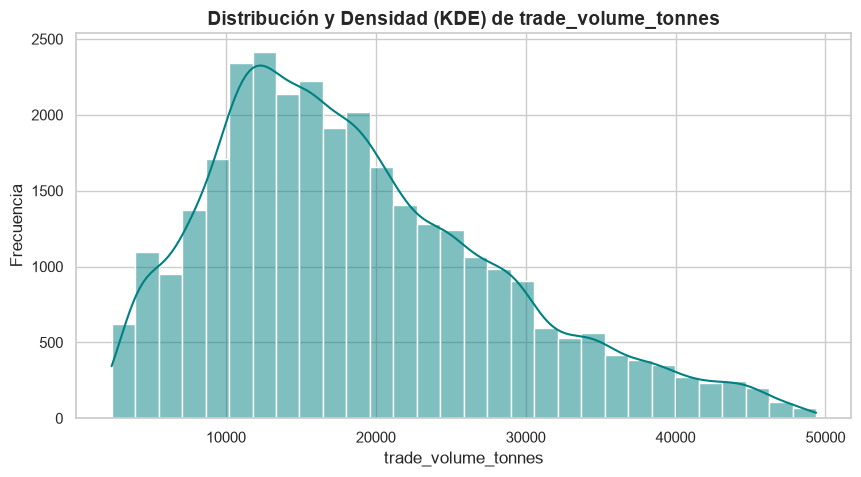

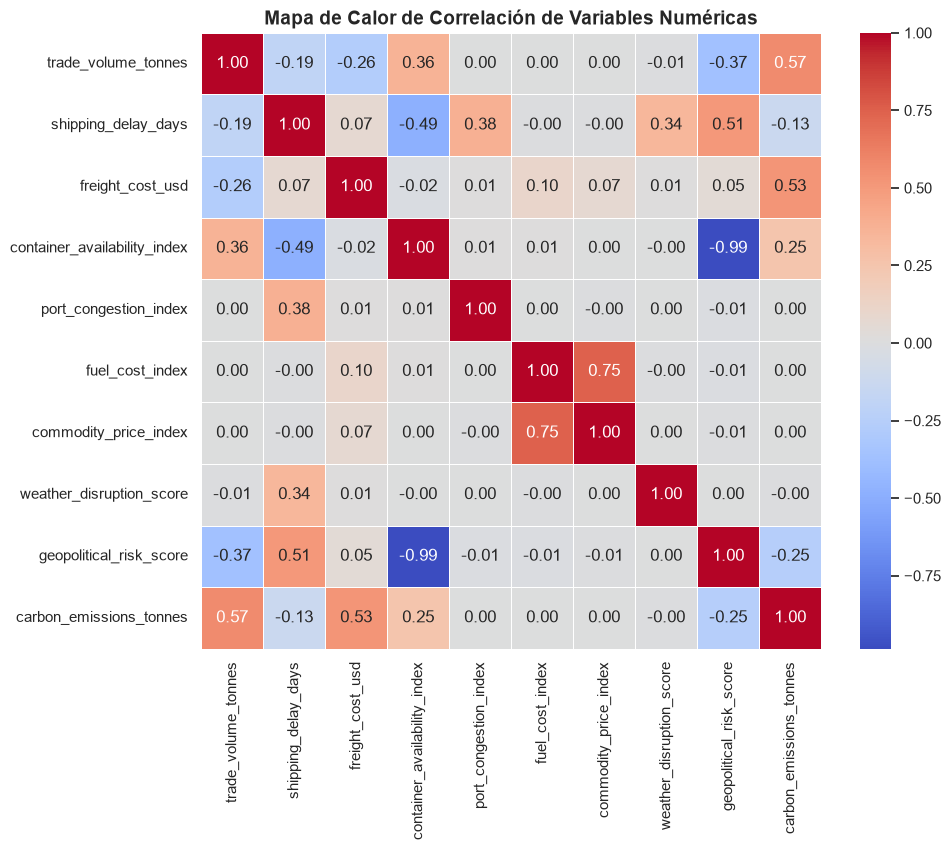

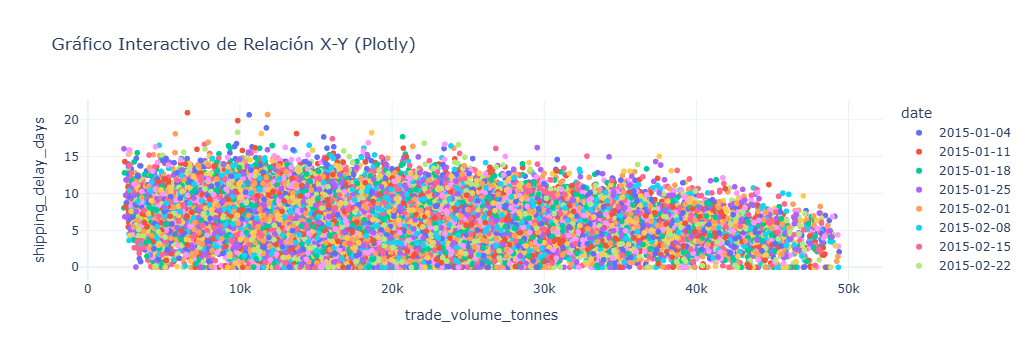

¡Gráfico interactivo guardado como 'grafico_interactivo.html'!


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Configurar el estilo visual estético
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Cargar el dataset limpio
df = pd.read_csv('dataset_limpio.csv')

# 1. Identificar automáticamente columnas numéricas y de texto para las gráficas
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print(f"Columnas numéricas detectadas: {numeric_cols}")
print(f"Columnas categóricas detectadas: {categorical_cols}")

# 2. GRÁFICO 1: Histograma y Densidad (KDE) de la primera métrica numérica
if len(numeric_cols) > 0:
    col_num = numeric_cols[0]
    plt.figure(figsize=(10, 5))
    sns.histplot(df[col_num], kde=True, color='teal', bins=30)
    plt.title(f'Distribución y Densidad (KDE) de {col_num}', fontsize=14, fontweight='bold')
    plt.xlabel(col_num, fontsize=12)
    plt.ylabel('Frecuencia', fontsize=12)
    plt.show()

# 3. GRÁFICO 2: Mapa de Calor de Correlación (Correlation Heatmap)
if len(numeric_cols) > 1:
    plt.figure(figsize=(10, 8))
    corr_matrix = df[numeric_cols].corr()
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
    plt.title('Mapa de Calor de Correlación de Variables Numéricas', fontsize=14, fontweight='bold')
    plt.show()

# 4. GRÁFICO 3: Gráfico de Dispersión Interactivo con Plotly
if len(numeric_cols) >= 2:
    fig = px.scatter(
        df, 
        x=numeric_cols[0], 
        y=numeric_cols[1], 
        color=categorical_cols[0] if len(categorical_cols) > 0 else None,
        title='Gráfico Interactivo de Relación X-Y (Plotly)',
        template='plotly_white'
    )
    fig.show()
    # Guardar componente interactivo como pide el proyecto
    fig.write_html("grafico_interactivo.html")
    print("¡Gráfico interactivo guardado como 'grafico_interactivo.html'!")